# REHAB24-6: 2D/3D elbow-angle benchmark with per-view calibration

Evaluates MediaPipe elbow-angle estimation against REHAB24-6 OptiTrack 3D ground truth.

**Variants:** `A_2D_Base` · `B_3D_World` · `D_2D_Calibrated` · `D_2D_PerView` · `D_3D_Calibrated`

**Inclusion (after Aguilar-Ortega et al., Sensors 2023, p.10):** angle evaluation is
restricted to recordings with expected flexion at the measured joint (ROM ≥ 60°),
an arm visible in ≥ 50% of frames, and temporal alignment r ≥ 0.7.

**Run all cells in order.**

In [39]:
# ============================================================
# STEP 1 — Python 3.12 environment for MediaPipe
# ============================================================
import os, subprocess

MP_PY = '/content/mpenv/bin/python'
if not os.path.exists(MP_PY):
    print('Installing uv and creating Python 3.12 env...')
    subprocess.run(['pip', 'install', '-q', 'uv'], check=True)
    subprocess.run(['uv', 'venv', '--python', '3.12', '/content/mpenv'], check=True)
    subprocess.run([
        'uv', 'pip', 'install', '--python', MP_PY,
        'numpy==1.26.4', 'mediapipe==0.10.14', 'pyyaml',
        'pandas', 'opencv-python', 'matplotlib',
        'scikit-learn', 'scipy',
    ], check=True)
print('MediaPipe Python 3.12 env ready at:', MP_PY)

MediaPipe Python 3.12 env ready at: /content/mpenv/bin/python


In [40]:
# ============================================================
# # STEP 2 — Locate dataset in Google Drive
# ============================================================
import urllib.request

ZENODO_BASE = 'https://zenodo.org/records/13305826/files'

def find_in_drive(filename):
    if not os.path.exists('/content/drive/MyDrive'):
        return None
    matches = glob.glob(f'/content/drive/MyDrive/**/{filename}', recursive=True)
    return matches[0] if matches else None

def ensure_file(filename, url_name=None):
    target = os.path.join(DATA, filename)
    if os.path.exists(target) and os.path.getsize(target) > 0:
        print(f'[OK]       {filename}')
        return target
    hit = find_in_drive(filename)
    if hit:
        print(f'[Drive]    {filename} <- {hit}')
        if not os.path.exists(target):
            os.symlink(hit, target)
        return target
    url = f"{ZENODO_BASE}/{url_name or filename}?download=1"
    print(f'[Download] {url}')
    urllib.request.urlretrieve(url, target)
    return target

# --- Segmentation.csv ---
for name in ('Segmentation.csv', 'Segmentation.txt'):
    hit = find_in_drive(name)
    if hit:
        dst = os.path.join(DATA, os.path.basename(hit))
        if not os.path.exists(dst):
            shutil.copy(hit, dst)
        break
if not glob.glob(f'{DATA}/Segmentation.*'):
    try: ensure_file('Segmentation.csv')
    except: ensure_file('Segmentation.txt')

# --- joints_names.txt ---
for name in ('joints_names.txt', 'joint_names.txt'):
    hit = find_in_drive(name)
    if hit:
        dst = os.path.join(DATA, os.path.basename(hit))
        if not os.path.exists(dst):
            shutil.copy(hit, dst)
        break
if not glob.glob(f'{DATA}/joint*names*.txt'):
    ensure_file('joints_names.txt')

# --- videos (Ex1..Ex6 structure OR videos.zip) ---
# First check if videos already extracted into Ex* folders
existing_mp4s = glob.glob(f'{DATA}/**/*.mp4', recursive=True) + \
                glob.glob(f'{DATA}/**/*.avi', recursive=True)
if not existing_mp4s:
    # try Drive zip
    drive_zip = find_in_drive('videos.zip')
    if drive_zip:
        target = os.path.join(DATA, 'videos.zip')
        if not os.path.exists(target):
            os.symlink(drive_zip, target)
        print('Extracting videos.zip...')
        with zipfile.ZipFile(target) as zf:
            zf.extractall(DATA)
    else:
        z = ensure_file('videos.zip')
        print('Extracting videos.zip...')
        with zipfile.ZipFile(z) as zf:
            zf.extractall(DATA)

# --- 3d_joints ---
existing_3d = glob.glob(f'{DATA}/3d_joints/**/*.*', recursive=True)
if not existing_3d:
    drive_3d_dir = None
    hits = glob.glob('/content/drive/MyDrive/**/3d_joints', recursive=True)
    if hits and os.path.isdir(hits[0]) and os.listdir(hits[0]):
        drive_3d_dir = hits[0]
    if drive_3d_dir:
        dst = os.path.join(DATA, '3d_joints')
        if not os.path.exists(dst):
            os.symlink(drive_3d_dir, dst)
        print(f'[Drive] Linked 3d_joints from {drive_3d_dir}')
    else:
        z = ensure_file('3d_joints.zip')
        print('Extracting 3d_joints.zip...')
        with zipfile.ZipFile(z) as zf:
            zf.extractall(DATA)

print('\nDATA contents:', os.listdir(DATA))
all_mp4s = glob.glob(f'{DATA}/**/*.mp4', recursive=True) + \
           glob.glob(f'{DATA}/**/*.avi', recursive=True)
print(f'Total video files found: {len(all_mp4s)}')
if all_mp4s:
    print('  Example:', all_mp4s[0])

[OK]       3d_joints.zip
Extracting 3d_joints.zip...

DATA contents: ['joints_names.txt', 'Ex2', 'Ex4', 'Ex6', 'Ex1', '3d_joints.zip', 'Ex3', 'Ex5', 'Segmentation.csv', 'videos.zip']
Total video files found: 130
  Example: /content/rehab24/Ex2/PM_110-Camera18-30fps-transposed.mp4


In [41]:
# ============================================================
# # STEP 3 — Settings, repo clone, recordings list
# ============================================================
import glob, os, shutil, subprocess, sys, time, zipfile
import numpy as np, pandas as pd

# reset working directory FIRST — prevents "No such file or directory" error
os.chdir('/content')

# ---- core settings ----
REPO_DIR         = '/content/repo'
BRANCH           = 'main'
REPO_URL         = 'https://github.com/suvini2001/AI-based-Physiotherapy-project-.git'
MP_PY            = '/content/mpenv/bin/python'
DATA             = '/content/rehab24'
MAX_VIDEOS       = None
EXERCISES        = [1, 2, 3]
THRESHOLD        = 0.70
MARGIN           = 45
MAX_LAG          = 30
MODEL_COMPLEXITY = 1

ARMS_OVERRIDE = {
    'right': ('12: RightArm', '13: RightForeArm', '14: RightHand'),
    'left':  ('7: LeftArm',   '8: LeftForeArm',   '9: LeftHand'),
}

# ---- mount Drive ----
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
CACHE   = '/content/drive/MyDrive/rehab24_cache_3d'
RESULTS = '/content/drive/MyDrive/rehab24_results_3d'
for d in (DATA, CACHE, RESULTS):
    os.makedirs(d, exist_ok=True)

# ---- remove any old clone and clone correct branch ----
if os.path.exists(REPO_DIR):
    shutil.rmtree(REPO_DIR)
assert not os.path.exists(REPO_DIR), "Could not remove old repo"
subprocess.run(
    ['git', 'clone', '-q', '-b', BRANCH, REPO_URL, REPO_DIR],
    check=True, cwd='/content'
)
os.chdir(REPO_DIR)
for p in (REPO_DIR,
          os.path.join(REPO_DIR, 'capture'),
          os.path.join(REPO_DIR, 'pose'),
          os.path.join(REPO_DIR, 'vision')):
    if p not in sys.path:
        sys.path.insert(0, p)
print('Branch:', BRANCH)

# ---- verify modules ----
import importlib.util
all_ok = True
for mod in ['angles', 'angles_world', 'benchmark_common',
            'calibration', 'filters', 'visibility']:
    spec = importlib.util.find_spec(mod)
    status = 'OK' if spec else 'MISSING!!!'
    if not spec: all_ok = False
    print(f'  {mod:20s}: {status}')
assert all_ok, "Some modules missing — check branch"

# ---- joint names ----
jn_files = glob.glob(f'{DATA}/**/*joint*names*.txt', recursive=True)
assert jn_files, "joints_names.txt not found — re-run Step 3 first"
with open(jn_files[0]) as f:
    JOINT_NAMES = [l.strip() for l in f if l.strip()]
print(f'Joint names: {len(JOINT_NAMES)} loaded')

for side, joints in ARMS_OVERRIDE.items():
    for jn in joints:
        assert jn in JOINT_NAMES, f"'{jn}' not in JOINT_NAMES"
print('ARMS_OVERRIDE: all joints verified OK')

# ---- segmentation ----
seg_files = glob.glob(f'{DATA}/**/Segmentation.*', recursive=True)
assert seg_files, "Segmentation.csv not found — re-run Step 3 first"
sep = ';' if ';' in open(seg_files[0]).readline() else ','
seg_df = pd.read_csv(seg_files[0], sep=sep)
cols_lower = {c.lower(): c for c in seg_df.columns}

def pick_col(candidates):
    for cand in candidates:
        for cl, orig in cols_lower.items():
            if cand in cl: return orig
    raise KeyError(f'No column matching {candidates}')

c_vid   = pick_col(['video_id', 'video', 'file', 'rec', 'name'])
c_ex    = pick_col(['exercise_id', 'exercise', 'activity', 'ex'])
c_start = pick_col(['first_frame', 'start', 'begin', 'f0', 'from'])
c_end   = pick_col(['last_frame',  'end',   'stop',  'f1', 'to'])
c_view  = None
for cl, orig in cols_lower.items():
    if any(k in cl for k in ['cam17_orientation', 'view', 'angle', 'cam_pos']):
        c_view = orig
        break
print(f'Columns: vid={c_vid}, ex={c_ex}, start={c_start}, end={c_end}, view={c_view}')

# ---- index files ----
all_videos = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in glob.glob(f'{DATA}/**/*.*', recursive=True)
    if p.lower().endswith(('.mp4', '.avi', '.mov'))
}
SKIP = {'joints_names.txt', 'joint_names.txt',
        'segmentation.csv', 'segmentation.txt'}
all_3d = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in glob.glob(f'{DATA}/**/*.*', recursive=True)
    if p.lower().endswith(('.npy', '.npz'))
    and os.path.basename(p).lower() not in SKIP
}
print(f'Videos: {len(all_videos)},  3D truth files: {len(all_3d)}')

# ---- build recordings ----
seg_ex = seg_df[seg_df[c_ex].isin(EXERCISES)].copy()
recordings = []
for (vid_id, ex_id), grp in seg_ex.groupby([c_vid, c_ex]):
    person_id = str(vid_id).strip()
    f0 = max(0, int(grp[c_start].min()) - MARGIN)
    f1 = int(grp[c_end].max()) + MARGIN
    view_val = str(grp[c_view].iloc[0]) if c_view else 'unknown'
    matched_vids = {k: v for k, v in all_videos.items()
                    if k.startswith(person_id + '-') or k == person_id}
    person_3d = {k: v for k, v in all_3d.items()
                 if k.startswith(person_id + '-') or k == person_id}
    if not person_3d: continue
    truth_key = next((k for k in person_3d if '30fps' in k),
                    next((k for k in person_3d if '120fps' in k), next(iter(person_3d))))
    for vid_key, vid_path in matched_vids.items():
        cam = ('cam18'  if 'cam18' in vid_key.lower() or 'transposed' in vid_key.lower()
               else 'cam17' if 'cam17' in vid_key.lower()
               else 'unknown')
        recordings.append({
            'rec_id':     f'{person_id}_ex{int(ex_id)}_{cam}',
            'video_key':  vid_key,
            'video_path': vid_path,
            'truth_path': person_3d[truth_key],
            'truth_key':  truth_key,
            'exercise':   int(ex_id),
            'f0': f0, 'f1': f1,
            'view_raw':   view_val,
            'cam':        cam,
            'cam_label':  ('cam18' if 'camera18' in vid_key.lower() or 'cam18' in vid_key.lower()
                           else 'cam17' if 'camera17' in vid_key.lower() or 'cam17' in vid_key.lower()
                           else 'unknown'),
        })

recordings = list({r['rec_id']: r for r in recordings}.values())
if MAX_VIDEOS:
    recordings = recordings[:MAX_VIDEOS]
print(f'Total recordings: {len(recordings)}')

# ---- cache status ----
cached_files = {os.path.basename(p) for p in glob.glob(f'{CACHE}/*.npz')}
matched = sum(1 for r in recordings
              if f"{r['rec_id']}_{r['f0']}_{r['f1']}_3d.npz" in cached_files)
print(f'Cache: {matched}/{len(recordings)} done — {len(recordings)-matched} remaining')
print('\nReady — now run Step 5')

Mounted at /content/drive
Branch: main
  angles              : OK
  angles_world        : OK
  benchmark_common    : OK
  calibration         : OK
  filters             : OK
  visibility          : OK
Joint names: 26 loaded
ARMS_OVERRIDE: all joints verified OK
Columns: vid=video_id, ex=exercise_id, start=first_frame, end=last_frame, view=cam17_orientation
Videos: 130,  3D truth files: 130
Total recordings: 70
Cache: 70/70 done — 0 remaining

Ready — now run Step 5


In [42]:
# ============================================================
# ROM SCAN — which recordings actually flex the elbow?
# (paper p.10: "only ... exercises where there is an expected flexion")
# ============================================================
import numpy as np, pandas as pd
import benchmark_common as bc

rows = []
for rec in recordings:
    truth_arr = bc.load_truth_array(rec['truth_path'], JOINT_NAMES)
    for side in ('right', 'left'):
        gt = bc.truth_elbow_3d(truth_arr, JOINT_NAMES, ARMS_OVERRIDE[side], use_dims=3)
        if np.isfinite(gt).any():
            rom = float(np.nanpercentile(gt, 95) - np.nanpercentile(gt, 5))
            rows.append((rec['exercise'], side, rec['rec_id'], rom))

df_rom = pd.DataFrame(rows, columns=['ex', 'side', 'rec_id', 'rom'])

MIN_ROM = 60.0        # must match the gate in Step 5
print(f'usable fraction (ROM >= {MIN_ROM:.0f} deg):')
print(df_rom.assign(ok=df_rom.rom >= MIN_ROM).groupby(['ex','side'])['ok'].mean().round(2))
print()
print('TOTAL usable:', int((df_rom.rom >= MIN_ROM).sum()), '/', len(df_rom))

usable fraction (ROM >= 60 deg):
ex  side 
1   left     0.0
    right    0.0
2   left     1.0
    right    1.0
3   left     1.0
    right    1.0
Name: ok, dtype: float64

TOTAL usable: 88 / 140


In [43]:
# ============================================================
# STEP 5 — Evaluation (A / B / E / G, then calibrated D / F / H)
# ============================================================
import numpy as np, os, subprocess, time, csv
import pandas as pd
import sys


from features import frame_features, overlap_rows, FEATURE_NAMES

import angles as angles_2d
from angles_lift import bone_lengths, elbow_angle_lifted, elbow_angle_hybrid, planarity
from angles_world import mask_world_like
import benchmark_common as bc
from benchmark_common import elbow_angle_3d_ordered
from benchmark_common import butterworth_filter
from visibility import mask_low_visibility
from calibration import fit_curve, apply_calibration, leave_one_person_out


def fill_1d(arr, max_gap=15):
    arr = np.array(arr, dtype=float)
    if np.isnan(arr).all() or not np.isnan(arr).any():
        return arr
    idx  = np.arange(len(arr))
    good = ~np.isnan(arr)
    filled = arr.copy()
    in_gap, gap_start = False, 0
    for i in range(len(arr)):
        if np.isnan(arr[i]) and not in_gap:
            in_gap, gap_start = True, i
        elif not np.isnan(arr[i]) and in_gap:
            in_gap = False
            if i - gap_start <= max_gap:
                filled[gap_start:i] = np.interp(
                    idx[gap_start:i], idx[good], arr[good])
    return filled


def infer_view(rec):
    """cam17_orientation describes the SUBJECT's orientation w.r.t. camera 17.
    It must not be reused as camera 18's viewpoint."""
    v   = str(rec.get('view_raw', '')).lower()
    cam = rec.get('cam_label', rec.get('cam', ''))

    if 'half' in v:                   subj = 'Half-profile'
    elif 'front' in v or v == '0':    subj = 'Front'
    elif 'prof' in v:                 subj = 'Profile'
    elif 'side' in v or '90' in v:    subj = 'Side'
    else:                             subj = 'Unknown'

    if cam == 'cam18':
        return f'{subj}/cam18'        # same subject pose, different camera
    return subj


def get_3d_landmarks(rec):
    cache_path = os.path.join(
        CACHE, f"{rec['rec_id']}_{rec['f0']}_{rec['f1']}_3d.npz")
    need_extract = True
    if os.path.exists(cache_path):
        try:
            d = np.load(cache_path)
            if 'world' in d.files and 'lm' in d.files and d['lm'].shape[0] > 0:
                need_extract = False
        except Exception:
            pass
    if need_extract:
        env = os.environ.copy()
        env['MPLBACKEND'] = 'Agg'
        env['PYTHONPATH'] = REPO_DIR
        cmd = [MP_PY, 'extract_world.py',
               rec['video_path'],
               str(rec['f0']), str(rec['f1']),
               cache_path, str(MODEL_COMPLEXITY)]
        subprocess.run(cmd, check=True, env=env, cwd=REPO_DIR)
    d = np.load(cache_path)
    return d['lm'], d['world'], tuple(d['size']), float(d['fps'])


def resample_to(t_target, t_src, values, max_gap_s=0.1):
    """Linear-interpolate 1-D values onto t_target. NaN-safe: a real mocap
    dropout stays NaN instead of being interpolated across."""
    values = np.asarray(values, float)
    good = np.isfinite(values)
    if good.sum() < 2:
        return np.full(len(t_target), np.nan)
    out = np.interp(t_target, t_src[good], values[good], left=np.nan, right=np.nan)
    if max_gap_s is not None:
        idx = np.searchsorted(t_src[good], t_target)
        idx = np.clip(idx, 1, good.sum() - 1)
        near = np.minimum(np.abs(t_target - t_src[good][idx]),
                          np.abs(t_target - t_src[good][idx - 1]))
        out[near > max_gap_s] = np.nan
    return out


def truth_angle_for(rec, truth_arr, world, npz_f0, fps, arm_joints):
    """gt angle on the VIDEO frame grid, whatever rate the truth file is."""
    TRUTH_FPS = 120.0 if '120fps' in str(rec.get('truth_key', '')) else 30.0
    if abs(TRUTH_FPS - fps) < 1.0:
        win = truth_arr[npz_f0: npz_f0 + len(world)]
        return bc.truth_elbow_3d(win, JOINT_NAMES, arm_joints, use_dims=3)
    gt_full = bc.truth_elbow_3d(truth_arr, JOINT_NAMES, arm_joints, use_dims=3)
    t_truth = np.arange(len(truth_arr)) / TRUTH_FPS
    t_video = (npz_f0 + np.arange(len(world))) / fps
    return resample_to(t_video, t_truth, gt_full)


def append_row(path, row):
    """Append one row dict to a CSV, creating the header if the file is new."""
    write_header = not os.path.exists(path) or os.path.getsize(path) == 0
    with open(path, 'a', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=row.keys())
        if write_header:
            writer.writeheader()
        writer.writerow(row)


# ---- one CSV per uncalibrated variant; the calibrated ones share path_D ----
path_A = os.path.join(RESULTS, 'variant_A_2d.csv')
path_B = os.path.join(RESULTS, 'variant_B_3d_world.csv')
path_D = os.path.join(RESULTS, 'variant_D_3d_calibrated.csv')
path_E = os.path.join(RESULTS, 'variant_E_lifted.csv')
path_G = os.path.join(RESULTS, 'variant_G_hybrid.csv')

# fresh start: append_row only appends, so stale rows would accumulate
for path in (path_A, path_B, path_D, path_E, path_G):
    if os.path.exists(path):
        os.remove(path)

skipped_align  = 0
skipped_static = 0
skipped_cov    = 0
MIN_ROM = 60.0        # Ex1 max 50.8 deg, Ex2/Ex3 min 80.4 deg -> clean split
MIN_COV = 50.0        # % of frames needing a usable 2D angle

rows_A, rows_B, rows_E, rows_G, aligned_cache = [], [], [], [], []

for idx, rec in enumerate(recordings, 1):
    try:
        t0 = time.time()
        lm, world, size, fps = get_3d_landmarks(rec)
        truth_arr = bc.load_truth_array(rec['truth_path'], JOINT_NAMES)

        npz_f0 = int(np.load(os.path.join(
            CACHE, f"{rec['rec_id']}_{rec['f0']}_{rec['f1']}_3d.npz"))['f0'])
        TRUTH_FPS = 120.0 if "120fps" in str(rec.get("truth_key", "")) else 30.0
        if abs(TRUTH_FPS - fps) < 1.0:
            truth_win = truth_arr[npz_f0: npz_f0 + len(world)]   # rates match
            t_video = t_truth = None
        else:
            truth_win = None                                      # interp needed
            t_truth = np.arange(len(truth_arr)) / TRUTH_FPS
            t_video = (npz_f0 + np.arange(len(world))) / fps

        lm_masked    = mask_low_visibility(lm, threshold=THRESHOLD)
        world_masked = mask_world_like(world, lm_masked)

        # bone lengths are a property of the person, so once per recording
        L = {s: bone_lengths(lm_masked, s, size) for s in ('right', 'left')}
        side_mae = {'right': float('nan'), 'left': float('nan')}

        for side in ('right', 'left'):
            arm_joints = ARMS_OVERRIDE[side]
            if truth_win is not None:
                gt_3d = bc.truth_elbow_3d(truth_win, JOINT_NAMES, arm_joints, use_dims=3)
            else:
                gt_full = bc.truth_elbow_3d(truth_arr, JOINT_NAMES, arm_joints, use_dims=3)
                gt_3d = resample_to(t_video, t_truth, gt_full)

            L_up, L_fo = L[side]

            # --- A: plain 2D projection ---
            pred_a_raw  = angles_2d.elbow_angle(lm_masked, side=side, size=size)
            pred_a_fill = fill_1d(pred_a_raw, max_gap=5)
            pred_a = (butterworth_filter(pred_a_fill, fs=fps, cutoff=6.0)
                      if np.isfinite(pred_a_fill).sum() > 15 else pred_a_fill)

            # --- B: MediaPipe world landmarks ---
            pred_b_raw  = elbow_angle_3d_ordered(world_masked, side=side)
            pred_b_fill = fill_1d(pred_b_raw, max_gap=5)
            pred_b = (butterworth_filter(pred_b_fill, fs=fps, cutoff=6.0)
                      if np.isfinite(pred_b_fill).sum() > 15 else pred_b_fill)

            # --- E: bone-length constrained 2.5D lift ---
            pred_e_raw  = elbow_angle_lifted(lm_masked, world_masked, side, size,
                                             L_up, L_fo)
            pred_e_fill = fill_1d(pred_e_raw, max_gap=5)
            pred_e = (butterworth_filter(pred_e_fill, fs=fps, cutoff=6.0)
                      if np.isfinite(pred_e_fill).sum() > 15 else pred_e_fill)

            # --- G: hybrid, 2D in-plane and lift out-of-plane ---
            pred_g_raw  = elbow_angle_hybrid(lm_masked, world_masked, side, size,
                                             L_up, L_fo)
            pred_g_fill = fill_1d(pred_g_raw, max_gap=5)
            pred_g = (butterworth_filter(pred_g_fill, fs=fps, cutoff=6.0)
                      if np.isfinite(pred_g_fill).sum() > 15 else pred_g_fill)

            # per-frame geometric features, same signals the benchmark scores
            feat_full = frame_features(lm_masked, world_masked, side, size,
                                       L_up, L_fo, pred_a, pred_b, pred_e)

            meta = {
                'recording': f"{rec['rec_id']}_{side}",
                'video':     rec['video_key'],
                'person':    bc.person_of(rec['video_key']),
                'ex':        rec['exercise'],
                'cam':       rec.get('cam_label', rec.get('cam', 'unknown')),
                'side':      side,
                'view':      infer_view(rec),
            }

            # --- gate 1: does this joint actually flex? (paper p.10) ---
            gt_range = (float(np.nanpercentile(gt_3d, 95) - np.nanpercentile(gt_3d, 5))
                        if np.isfinite(gt_3d).any() else float('nan'))
            meta = dict(meta, gt_range=round(gt_range, 1) if gt_range == gt_range else None)

            if not (gt_range >= MIN_ROM):
                skipped_static += 1
                print(f"    static {side}: ROM {gt_range:.1f}deg < {MIN_ROM:.0f} "
                      f"- no expected flexion")
                continue

            # --- gate 1b: is this arm visible at all? ---
            cov_a = 100.0 * float(np.isfinite(pred_a).mean())
            meta = dict(meta, cov_pred=round(cov_a, 1))

            if cov_a < MIN_COV:
                skipped_cov += 1
                print(f"    occluded {side}: coverage {cov_a:.1f}% "
                      f"(ROM {gt_range:.0f}deg is fine) - arm hidden from this camera")
                continue

            # --- gate 2: temporal alignment, one lag for every variant ---
            lag, lag_r = bc.best_lag(pred_a, gt_3d, max_lag=MAX_LAG, filter_signals=True)
            pa_al, gt_al = bc.overlap(pred_a, gt_3d, lag)
            pb_al, _     = bc.overlap(pred_b, gt_3d, lag)
            pe_al, _     = bc.overlap(pred_e, gt_3d, lag)
            pg_al, _     = bc.overlap(pred_g, gt_3d, lag)
            feat_al, _   = overlap_rows(feat_full, gt_3d, lag)
            meta = dict(meta, lag=lag, lag_r=round(float(lag_r), 3))

            if abs(lag) >= MAX_LAG or lag_r < 0.7:
                skipped_align += 1
                why = "lag pinned" if abs(lag) >= MAX_LAG else "weak tracking"
                print(f"    reject {side}: {why}  lag={lag} r={lag_r:.2f} "
                      f"ROM={gt_range:.0f}deg cov={cov_a:.0f}%")
                continue

            # every row is built after the gate, from the same aligned signals
            row_a = bc.make_row("A_2D_Base",   pa_al, gt_al, meta)
            row_b = bc.make_row("B_3D_World",  pb_al, gt_al, meta)
            row_e = bc.make_row("E_2D_Lifted", pe_al, gt_al, meta)
            row_g = bc.make_row("G_Hybrid",    pg_al, gt_al, meta)

            if row_b:
                rows_B.append(row_b)
                append_row(path_B, row_b)
                side_mae[side] = row_b["mae"]
            if row_e:
                rows_E.append(row_e)
                append_row(path_E, row_e)
            if row_g:
                rows_G.append(row_g)
                append_row(path_G, row_g)
            if row_a:
                rows_A.append(row_a)
                append_row(path_A, row_a)
                aligned_cache.append({"meta":      meta,
                                      "pred_2d":   pa_al,
                                      "pred_3d":   pb_al,
                                      "pred_lift": pe_al,
                                      "pred_hyb":  pg_al,
                                      "feat":      feat_al,
                                      "truth_3d":  gt_al})

        elapsed = time.time() - t0
        mae_r, mae_l = side_mae['right'], side_mae['left']
        print(f'[{idx}/{len(recordings)}] {rec["rec_id"]}  '
              f'{elapsed:.1f}s  MAE R/L: {mae_r:.1f}deg/{mae_l:.1f}deg')

    except Exception as e:
        import traceback
        print(f'[{idx}/{len(recordings)}] SKIPPED {rec["rec_id"]}: {e}')
        traceback.print_exc()


print(f"\nSkipped (no flexion, ROM < {MIN_ROM:.0f}deg)  : {skipped_static}")
print(f"Skipped (occluded, cov < {MIN_COV:.0f}%)       : {skipped_cov}")
print(f"Skipped (poor tracking, r < 0.7)      : {skipped_align}")
print(f"Kept                                  : {len(rows_A)}")

# ---- calibrated variants: leave-one-person-out, global and per-view ----
rows_D = []
for item in aligned_cache:
    me   = item['meta']
    pool = [x for x in aligned_cache if x['meta']['person'] != me['person']]
    if not pool:
        continue
    same_view = [x for x in pool if x['meta']['view'] == me['view']]

    jobs = [('pred_2d',   pool,      'D_2D_Calibrated'),
            ('pred_3d',   pool,      'D_3D_Calibrated'),
            ('pred_2d',   same_view, 'D_2D_PerView'),
            ('pred_lift', same_view, 'F_Lift_PerView'),
            ('pred_hyb',  same_view, 'H_Hybrid_PerView')]

    for key, train, label in jobs:
        if label.endswith('PerView') and len(train) < 3:
            train = pool                      # fallback: too little same-view data
        pred_cal = item[key]
        p_cat = np.concatenate([x[key]        for x in train])
        t_cat = np.concatenate([x['truth_3d'] for x in train])
        valid = np.isfinite(p_cat) & np.isfinite(t_cat)
        if valid.sum() > 20:
            try:
                params = fit_curve(p_cat[valid], t_cat[valid], min_count=15)
                pred_cal = apply_calibration(item[key], params)
            except ValueError as e:
                print(f'  calib skip ({label}):', e)
        row = bc.make_row(label, pred_cal, item['truth_3d'], dict(me))
        if row:
            rows_D.append(row)
            append_row(path_D, row)

print(f'\nDone. Rows: A={len(rows_A)}, B={len(rows_B)}, '
      f'E={len(rows_E)}, G={len(rows_G)}, D={len(rows_D)}')


    static right: ROM 30.3deg < 60 - no expected flexion
    static left: ROM 2.5deg < 60 - no expected flexion
[1/70] PM_000_ex1_unknown  0.2s  MAE R/L: nandeg/nandeg
    static right: ROM 30.3deg < 60 - no expected flexion
    static left: ROM 2.5deg < 60 - no expected flexion
[2/70] PM_000_ex1_cam18  0.1s  MAE R/L: nandeg/nandeg


/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/content/repo/angles_lift.py:237: RuntimeWarning: All-NaN slice encountered
  out = np.nanmedian(stack, axis=0)


    static right: ROM 11.7deg < 60 - no expected flexion
    static left: ROM 3.7deg < 60 - no expected flexion
[3/70] PM_001_ex1_unknown  0.4s  MAE R/L: nandeg/nandeg
    static right: ROM 11.7deg < 60 - no expected flexion
    static left: ROM 3.7deg < 60 - no expected flexion
[4/70] PM_001_ex1_cam18  0.3s  MAE R/L: nandeg/nandeg
    static right: ROM 13.5deg < 60 - no expected flexion
    static left: ROM 2.1deg < 60 - no expected flexion
[5/70] PM_002_ex1_unknown  0.2s  MAE R/L: nandeg/nandeg
    static right: ROM 13.5deg < 60 - no expected flexion
    static left: ROM 2.1deg < 60 - no expected flexion
[6/70] PM_002_ex1_cam18  0.3s  MAE R/L: nandeg/nandeg
    occluded right: coverage 0.0% (ROM 105deg is fine) - arm hidden from this camera
[7/70] PM_003_ex2_cam18  0.4s  MAE R/L: nandeg/15.7deg
[8/70] PM_003_ex2_unknown  0.5s  MAE R/L: 15.0deg/10.9deg
    reject right: weak tracking  lag=-1 r=0.66 ROM=95deg cov=61%
[9/70] PM_004_ex2_cam18  0.3s  MAE R/L: nandeg/11.1deg
    occluded l

# Training- ML regression

In [44]:
import numpy as np, pandas as pd
from features import FEATURE_NAMES

X, y, grp, rid, pos = [], [], [], [], []
for i, item in enumerate(aligned_cache):
    F = np.asarray(item['feat'], float)
    t = np.asarray(item['truth_3d'], float)
    n = min(len(F), len(t)); F, t = F[:n], t[:n]
    ok = np.isfinite(F[:, FEATURE_NAMES.index('angle_2d')]) & np.isfinite(t)
    if ok.sum() < 50:
        continue

    X.append(F[ok]); y.append(t[ok])
    grp.append(np.full(ok.sum(), item['meta']['person']))
    rid.append(np.full(ok.sum(), i))
    pos.append(np.where(ok)[0])

X   = np.vstack(X)
y   = np.concatenate(y)
grp = np.concatenate(grp)
rid = np.concatenate(rid)
pos = np.concatenate(pos)

print(f'frames {X.shape[0]:,}   features {X.shape[1]}   persons {len(set(grp))}')
print(pd.DataFrame(X, columns=FEATURE_NAMES).describe().T[['mean','std','min','max']].round(2))

frames 149,973   features 20   persons 22
               mean    std    min     max
angle_2d     121.16  50.93  -8.26  187.12
angle_world  130.44  26.89  32.38  179.30
angle_lift   121.41  34.73  11.30  181.83
plan_upper     0.85   0.16   0.00    1.62
plan_fore      0.85   0.14   0.00    1.70
plan_min       0.79   0.17   0.00    1.57
len_upper      1.27   0.96   0.01    8.32
len_fore       1.25   0.93   0.00    7.41
bone_upper     1.53   1.13   0.74    5.45
bone_fore      1.49   1.07   0.64    4.74
sw_frac        0.10   0.04   0.00    0.23
vis_sh         1.00   0.00   0.99    1.00
vis_el         0.98   0.05   0.70    1.00
vis_wr         0.96   0.05   0.70    1.00
wz_sh_el       0.06   0.08  -0.25    0.29
wz_el_wr       0.07   0.08  -0.29    0.30
torso_ratio    0.49   0.22   0.01    2.93
d_angle       -0.00   4.17 -67.53   69.73
std_angle      7.18   9.99   0.00   81.37
is_right       0.51   0.50   0.00    1.00


# Traning the model

In [45]:
from sklearn.model_selection import GroupKFold
try:
    import lightgbm as lgb
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'lightgbm'], check=True)
    import lightgbm as lgb

PARAMS = dict(n_estimators=400, learning_rate=0.05, num_leaves=31,
              min_child_samples=50, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, random_state=0, verbose=-1)

# GROUPED by person — frames from one person are never split across folds
gkf  = GroupKFold(n_splits=min(8, len(set(grp))))
pred = np.full(len(y), np.nan)

for k, (tr, te) in enumerate(gkf.split(X, y, groups=grp), 1):
    m = lgb.LGBMRegressor(**PARAMS).fit(X[tr], y[tr])
    pred[te] = m.predict(X[te])
    print(f'  fold {k}: train {len(tr):,}  test {len(te):,}  '
          f'held-out persons {sorted(set(grp[te]))}')

print(f'\nout-of-fold MAE : {np.abs(pred - y).mean():.2f} deg')
print(f'out-of-fold RMSE: {np.sqrt(((pred - y)**2).mean()):.2f} deg')

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


  fold 1: train 130,788  test 19,185  held-out persons [np.str_('PM_107'), np.str_('PM_110')]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


  fold 2: train 130,903  test 19,070  held-out persons [np.str_('PM_003'), np.str_('PM_030'), np.str_('PM_031')]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


...

  fold 6: train 131,491  test 18,482  held-out persons [np.str_('PM_013'), np.str_('PM_026'), np.str_('PM_033')]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


  fold 7: train 130,905  test 19,068  held-out persons [np.str_('PM_010'), np.str_('PM_040'), np.str_('PM_044')]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


  fold 8: train 131,081  test 18,892  held-out persons [np.str_('PM_014'), np.str_('PM_108'), np.str_('PM_119')]

out-of-fold MAE : 10.98 deg
out-of-fold RMSE: 15.09 deg


# Variant එකක් විදිහට ඇගයීම

In [46]:
path_I = os.path.join(RESULTS, 'variant_I_ml.csv')
if os.path.exists(path_I):
    os.remove(path_I)

rows_I = []
for i, item in enumerate(aligned_cache):
    n = min(len(item['feat']), len(item['truth_3d']))
    full = np.full(n, np.nan)                  # NaN where features were missing
    m = rid == i
    if m.sum() == 0:
        continue
    full[pos[m]] = pred[m]                     # out-of-fold predictions only
    row = bc.make_row("I_ML_Features", full,
                      np.asarray(item['truth_3d'], float)[:n], dict(item['meta']))
    if row:
        rows_I.append(row)
        append_row(path_I, row)

print(f'I_ML_Features rows: {len(rows_I)}')

I_ML_Features rows: 56


# Comparing

In [47]:
import glob
df = pd.concat([pd.read_csv(f) for f in glob.glob(os.path.join(RESULTS,'variant_*.csv'))],
               ignore_index=True)
df['subj'] = df['view'].str.replace('/cam18', '', regex=False)

print(df.groupby('variant')[['mae','rmse','bias','r','coverage']].median().round(2))
print()
print(df.pivot_table(index='subj', columns='variant', values='mae', aggfunc='median').round(2))

                    mae   rmse   bias     r  coverage
variant                                              
A_2D_Base         16.12  23.83   7.99  0.91     98.63
B_3D_World        21.93  26.56  14.90  0.89     98.37
D_2D_Calibrated   14.19  18.51   3.79  0.93     98.63
D_2D_PerView      13.33  17.85   2.46  0.93     98.63
D_3D_Calibrated   15.02  19.37   4.46  0.91     98.37
E_2D_Lifted       19.44  25.04   4.36  0.80     95.13
F_Lift_PerView    18.98  26.18   2.74  0.81     95.13
G_Hybrid          16.31  21.59   8.29  0.91     98.63
H_Hybrid_PerView  13.72  17.16   3.83  0.92     98.63
I_ML_Features     10.80  14.17   0.40  0.96     98.63

variant       A_2D_Base  B_3D_World  D_2D_Calibrated  D_2D_PerView  \
subj                                                                 
Front             13.61       23.30            11.06         11.32   
Half-profile      14.94       21.51            11.41         11.14   
Profile           19.83       21.85            16.50         14.50   



# Control එකක් — feature එකක් පමණක්

In [48]:
i2d = FEATURE_NAMES.index('angle_2d')
pred1 = np.full(len(y), np.nan)
for tr, te in gkf.split(X, y, groups=grp):
    m1 = lgb.LGBMRegressor(**PARAMS).fit(X[tr][:, [i2d]], y[tr])
    pred1[te] = m1.predict(X[te][:, [i2d]])

print(f'angle_2d only   : {np.abs(pred1 - y).mean():.2f} deg')
print(f'all 20 features : {np.abs(pred  - y).mean():.2f} deg')
print(f'the extra features are worth {np.abs(pred1-y).mean() - np.abs(pred-y).mean():.2f} deg')

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

angle_2d only   : 14.26 deg
all 20 features : 10.98 deg
the extra features are worth 3.28 deg


# කුමන features වැදගත්ද

In [49]:
m_all = lgb.LGBMRegressor(**PARAMS).fit(X, y)
imp = pd.Series(m_all.feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False)
print(imp.head(12))

bone_upper     1165
sw_frac         929
torso_ratio     857
angle_2d        756
bone_fore       746
vis_sh          734
angle_world     638
vis_wr          633
wz_el_wr        629
wz_sh_el        612
vis_el          606
plan_fore       534
dtype: int32


In [50]:
# ============================================================
# ML CHECKS — A: is the gain real?   B: does it generalise?
# ============================================================
import numpy as np, pandas as pd, lightgbm as lgb
from features import FEATURE_NAMES

Xdf = pd.DataFrame(X, columns=FEATURE_NAMES)     # also silences the feature-name warning

def oof(cols):
    """Out-of-fold predictions, folds grouped by person."""
    p = np.full(len(y), np.nan)
    for tr, te in gkf.split(Xdf, y, groups=grp):
        m = lgb.LGBMRegressor(**PARAMS).fit(Xdf.iloc[tr][cols], y[tr])
        p[te] = m.predict(Xdf.iloc[te][cols])
    return p

print('='*66)
print('CHECK A — where does the gain actually come from?')
print('='*66)

CONST     = ['bone_upper', 'bone_fore', 'sw_frac', 'is_right']   # constant per recording
per_frame = [c for c in FEATURE_NAMES if c not in CONST]

p_2d  = oof(['angle_2d'])
p_pf  = oof(per_frame)
p_all = oof(FEATURE_NAMES)

for name, p in (('angle_2d only',            p_2d),
                ('per-frame features only',  p_pf),
                ('all 20 features',          p_all)):
    print(f'  {name:26}  MAE {np.abs(p-y).mean():5.2f}   r {np.corrcoef(p, y)[0,1]:.3f}')

gain_geom  = np.abs(p_2d - y).mean() - np.abs(p_pf  - y).mean()
gain_const = np.abs(p_pf - y).mean() - np.abs(p_all - y).mean()
print()
print(f'  per-frame geometry is worth          {gain_geom:+5.2f} deg   <-- deployable')
print(f'  constant-per-recording is worth      {gain_const:+5.2f} deg   <-- may not transfer')

print()
print('='*66)
print('CHECK B — does it hold up on a viewpoint it never saw?')
print('='*66)

view = np.array([aligned_cache[i]['meta']['view'].replace('/cam18', '') for i in rid])
print('  frames per viewpoint:', dict(pd.Series(view).value_counts()))
print()

i2d = FEATURE_NAMES.index('angle_2d')
for held in sorted(set(view)):
    tr, te = (view != held), (view == held)
    if te.sum() < 500 or len(set(grp[tr])) < 3:
        print(f'  {held:14} skipped (too little data)')
        continue
    m  = lgb.LGBMRegressor(**PARAMS).fit(Xdf[tr], y[tr])
    pv = m.predict(Xdf[te])
    raw = np.abs(X[te, i2d] - y[te]).mean()
    print(f'  trained WITHOUT {held:14} -> MAE on {held:14} '
          f'{np.abs(pv - y[te]).mean():5.2f}   (raw 2D there: {raw:5.2f})')

CHECK A — where does the gain actually come from?
  angle_2d only               MAE 14.26   r 0.882
  per-frame features only     MAE 10.49   r 0.937
  all 20 features             MAE 10.98   r 0.933

  per-frame geometry is worth          +3.77 deg   <-- deployable
  constant-per-recording is worth      -0.49 deg   <-- may not transfer

CHECK B — does it hold up on a viewpoint it never saw?
  frames per viewpoint: {'Front': np.int64(89287), 'Profile': np.int64(37382), 'Half-profile': np.int64(23304)}

  trained WITHOUT Front          -> MAE on Front          10.34   (raw 2D there: 16.86)
  trained WITHOUT Half-profile   -> MAE on Half-profile   10.69   (raw 2D there: 17.43)
  trained WITHOUT Profile        -> MAE on Profile        18.63   (raw 2D there: 19.40)


# OM මර්දනය වෙනවද

In [35]:
def rom(a):
    a = np.asarray(a, float)
    return np.nanpercentile(a,95) - np.nanpercentile(a,5)
rr = []
for i, item in enumerate(aligned_cache):
    m = rid == i
    if m.sum() < 50: continue
    t = rom(y[m])
    if t > 0:
        rr.append(rom(pred[m]) / t)
print(f'ML  ROM/truth: median {np.median(rr):.3f}   (per-view cal was 0.945)')

ML  ROM/truth: median 0.916   (per-view cal was 0.945)


# Browser එකට export

In [36]:
import json
final = lgb.LGBMRegressor(**PARAMS).fit(X, y)       # all persons, for deployment
model_json = final.booster_.dump_model()
out = {'features': FEATURE_NAMES,
       'n_trees': len(model_json['tree_info']),
       'model': model_json}
p = os.path.join(RESULTS, 'elbow_ml_model.json')
json.dump(out, open(p, 'w'))
print(p, f'{os.path.getsize(p)/1024:.0f} KB')

/content/drive/MyDrive/rehab24_results_3d/elbow_ml_model.json 4470 KB


In [51]:
import pandas as pd, glob, os
df = pd.concat([pd.read_csv(f) for f in glob.glob(os.path.join(RESULTS,'variant_*.csv'))],
               ignore_index=True)
df['subj'] = df['view'].str.replace('/cam18', '', regex=False)
print('variants:', dict(df.variant.value_counts()))
print()
print(df.groupby('variant')[['mae','rmse','bias','r','coverage']].median().round(2))
print()
print(df.pivot_table(index='subj', columns='variant', values='mae', aggfunc='median').round(2))

variants: {'G_Hybrid': np.int64(56), 'A_2D_Base': np.int64(56), 'B_3D_World': np.int64(56), 'E_2D_Lifted': np.int64(56), 'I_ML_Features': np.int64(56), 'D_2D_Calibrated': np.int64(56), 'D_3D_Calibrated': np.int64(56), 'D_2D_PerView': np.int64(56), 'F_Lift_PerView': np.int64(56), 'H_Hybrid_PerView': np.int64(56)}

                    mae   rmse   bias     r  coverage
variant                                              
A_2D_Base         16.12  23.83   7.99  0.91     98.63
B_3D_World        21.93  26.56  14.90  0.89     98.37
D_2D_Calibrated   14.19  18.51   3.79  0.93     98.63
D_2D_PerView      13.33  17.85   2.46  0.93     98.63
D_3D_Calibrated   15.02  19.37   4.46  0.91     98.37
E_2D_Lifted       19.44  25.04   4.36  0.80     95.13
F_Lift_PerView    18.98  26.18   2.74  0.81     95.13
G_Hybrid          16.31  21.59   8.29  0.91     98.63
H_Hybrid_PerView  13.72  17.16   3.83  0.92     98.63
I_ML_Features     10.80  14.17   0.40  0.96     98.63

variant       A_2D_Base  B_3D_World 

In [10]:
import inspect, angles_lift
print(inspect.signature(angles_lift.lift_segments))

(landmarks, world, side='right', size=(640, 480), L_up=None, L_fo=None, sign_window=9, full_plane=0.95, depth_smooth=5)


In [11]:
import pandas as pd, glob, os
df = pd.concat([pd.read_csv(f) for f in glob.glob(os.path.join(RESULTS,'variant_*.csv'))],
               ignore_index=True)
df['subj'] = df['view'].str.replace('/cam18', '', regex=False)
print('variants:', dict(df.variant.value_counts()))
print()

print('='*70); print('OVERALL'); print('='*70)
print(df.groupby('variant')[['mae','rmse','bias','r','coverage']].median().round(2))

print()
print('='*70); print('BY SUBJECT ORIENTATION  <-- the real test'); print('='*70)
print(df.pivot_table(index='subj', columns='variant', values='mae',
                     aggfunc='median').round(2))

print()
print('='*70); print('PROFILE ONLY (out-of-plane)'); print('='*70)
print(df[df.subj=='Profile'].groupby('variant')[['mae','bias','coverage']]
        .agg(['count','median']).round(2))

print()
print('='*70); print('FRONT ONLY (sanity check - E should match A here)'); print('='*70)
print(df[df.subj=='Front'].groupby('variant')[['mae','bias','coverage']]
        .agg(['count','median']).round(2))

variants: {'G_Hybrid': np.int64(56), 'A_2D_Base': np.int64(56), 'B_3D_World': np.int64(56), 'E_2D_Lifted': np.int64(56), 'D_2D_Calibrated': np.int64(56), 'D_3D_Calibrated': np.int64(56), 'D_2D_PerView': np.int64(56), 'F_Lift_PerView': np.int64(56), 'H_Hybrid_PerView': np.int64(56)}

OVERALL
                    mae   rmse   bias     r  coverage
variant                                              
A_2D_Base         16.12  23.83   7.99  0.91     98.63
B_3D_World        21.93  26.56  14.90  0.89     98.37
D_2D_Calibrated   14.19  18.51   3.79  0.93     98.63
D_2D_PerView      13.33  17.85   2.46  0.93     98.63
D_3D_Calibrated   15.02  19.37   4.46  0.91     98.37
E_2D_Lifted       19.44  25.04   4.36  0.80     95.13
F_Lift_PerView    18.98  26.18   2.74  0.81     95.13
G_Hybrid          16.31  21.59   8.29  0.91     98.63
H_Hybrid_PerView  13.72  17.16   3.83  0.92     98.63

BY SUBJECT ORIENTATION  <-- the real test
variant       A_2D_Base  B_3D_World  D_2D_Calibrated  D_2D_PerView  \
s

In [12]:
# how often does the depth sign flip? — the lift's real bottleneck
from angles_lift import ARM, robust_scale
import numpy as np
flips = []
for rec in recordings[:25]:
    lm, world, size, fps = get_3d_landmarks(rec)
    lmm = mask_low_visibility(lm, threshold=THRESHOLD)
    w   = mask_world_like(world, lmm)
    for side in ('right','left'):
        sh, el, wr = ARM[side]
        for a, b, nm in ((sh, el, 'upper'), (wr, el, 'fore')):
            s = np.sign(w[:, a, 2] - w[:, b, 2])
            s = s[np.isfinite(s) & (s != 0)]
            if len(s) > 50:
                flips.append(dict(rec=rec['rec_id'], side=side, seg=nm,
                                  flip_pct=100*np.mean(np.diff(s) != 0)))
import pandas as pd
f = pd.DataFrame(flips)
print(f.groupby('seg')['flip_pct'].describe()[['count','50%','max']].round(1))
print()
print('recordings where the sign flips on >5% of frames:',
      f'{100*np.mean(f.flip_pct > 5):.0f}%')

       count  50%   max
seg                    
fore    42.0  0.9  10.1
upper   42.0  0.6   6.4

recordings where the sign flips on >5% of frames: 11%


In [ ]:
import pandas as pd, glob, os
df = pd.concat([pd.read_csv(f) for f in glob.glob(os.path.join(RESULTS,'variant_*.csv'))],
               ignore_index=True)
print('rows:', len(df))
print(df.variant.value_counts())

rows: 280
variant
B_3D_World         56
A_2D_Base          56
D_2D_Calibrated    56
D_3D_Calibrated    56
D_2D_PerView       56
Name: count, dtype: int64


In [ ]:
print('--- overall ---')
print(df.groupby('variant')[['mae','rmse','bias','r','share_gt20']].median().round(2))
print()
A = df.copy()
A['subj'] = A['view'].str.replace('/cam18', '', regex=False)
print('--- by camera x subject orientation ---')
print(A[A.variant.isin(['A_2D_Base','D_2D_Calibrated','D_2D_PerView'])]
        .groupby(['variant','cam','subj'])[['mae','bias']]
        .agg(['count','median']).round(2))

--- overall ---
                   mae   rmse   bias     r  share_gt20
variant                                               
A_2D_Base        16.12  23.83   7.99  0.91       30.40
B_3D_World       21.93  26.56  14.90  0.89       48.69
D_2D_Calibrated  14.19  18.51   3.79  0.93       20.80
D_2D_PerView     13.33  17.85   2.46  0.93       19.28
D_3D_Calibrated  15.02  19.37   4.46  0.91       25.85

--- by camera x subject orientation ---
                                     mae         bias       
                                   count median count median
variant         cam   subj                                  
A_2D_Base       cam17 Front           18  12.00    18  -1.31
                      Half-profile     5  17.70     5   2.24
                      Profile         10  16.77    10  13.18
                cam18 Front            6  24.70     6   8.49
                      Half-profile     4  13.76     4  -3.81
                      Profile         13  20.23    13  19.09
D_2D_Cali

In [13]:
print(pd.crosstab(df[df.variant=='A_2D_Base'].ex,
                  df[df.variant=='A_2D_Base'].view))
print()
print(df[df.variant=='A_2D_Base'].groupby(['ex','cam','view'])['mae'].agg(['count','median']).round(2))

view  Front  Front/cam18  Half-profile  Half-profile/cam18  Profile  \
ex                                                                    
2        18            6             5                   4        0   
3         0            0             0                   0       10   

view  Profile/cam18  
ex                   
2                 0  
3                13  

                             count  median
ex cam   view                             
2  cam17 Front                  18   12.00
         Half-profile            5   17.70
   cam18 Front/cam18             6   24.70
         Half-profile/cam18      4   13.76
3  cam17 Profile                10   16.77
   cam18 Profile/cam18          13   20.23


In [14]:
def rom(a):
    a = np.asarray(a, float)
    return (np.nanpercentile(a,95) - np.nanpercentile(a,5)
            if np.isfinite(a).any() else np.nan)

import collections
acc = collections.defaultdict(list)
for item in aligned_cache:
    me = item['meta']
    pool = [x for x in aligned_cache if x['meta']['person'] != me['person']]
    same = [x for x in pool if x['meta']['view'] == me['view']] or pool
    t = rom(item['truth_3d'])
    if not np.isfinite(t) or t <= 0:
        continue
    acc['raw'].append(rom(item['pred_2d']) / t)
    for train, name in ((pool,'global'), (same,'perview')):
        p_cat = np.concatenate([x['pred_2d']  for x in train])
        t_cat = np.concatenate([x['truth_3d'] for x in train])
        v = np.isfinite(p_cat) & np.isfinite(t_cat)
        try:
            prm = fit_curve(p_cat[v], t_cat[v], min_count=15)
            acc[name].append(rom(apply_calibration(item['pred_2d'], prm)) / t)
        except ValueError:
            pass

for k in ('raw','global','perview'):
    v = [x for x in acc[k] if np.isfinite(x)]
    if v:
        print(f'{k:8} ROM/truth  median {np.median(v):.3f}   '
              f'spread {min(v):.2f}-{max(v):.2f}   n={len(v)}')

raw      ROM/truth  median 1.075   spread 0.29-1.73   n=56
global   ROM/truth  median 0.863   spread 0.33-1.16   n=56
perview  ROM/truth  median 0.945   spread 0.38-1.20   n=56


In [15]:
from calibration import leave_one_person_out

records = [dict(person=x['meta']['person'], raw=x['pred_2d'], truth=x['truth_3d'])
           for x in aligned_cache]
lopo = leave_one_person_out(records)
print(lopo[['person','n','mae_raw','mae_cal','gt20_raw','gt20_cal',
            'range_raw','range_cal','range_truth']].round(2))
print()
print('range_cal / range_truth =',
      round(lopo.range_cal.median()/lopo.range_truth.median(), 3), '  <-- want ~1.0')
print('mae  :', round(lopo.mae_raw.median(),2), '->', round(lopo.mae_cal.median(),2))
print('gt20 :', round(lopo.gt20_raw.median(),1), '% ->', round(lopo.gt20_cal.median(),1), '%')

    person      n  mae_raw  mae_cal  gt20_raw  gt20_cal  range_raw  range_cal  \
0   PM_003  12827    13.84    15.08     18.09     30.62     126.29     103.57   
1   PM_004   5363    19.52    13.86     35.15     21.14     159.55     108.45   
2   PM_010   6489    12.68    12.49     19.76     19.12     101.71      87.90   
3   PM_011   3779    20.28    19.70     35.06     35.62      78.22      78.99   
4   PM_013   1760     7.67     6.08      0.00      0.00     107.65      92.81   
5   PM_014   9401    17.47    12.17     34.56     15.45     128.77     104.73   
6   PM_025   4747     8.66     6.85     10.43      1.85     141.12     117.53   
7   PM_026   6013    12.59     9.49     16.55      8.81     131.55     103.60   
8   PM_030   3778    19.96    16.31     38.70     29.57      85.31      83.58   
9   PM_031   2465    25.12    20.47     52.21     44.91     104.87      90.88   
10  PM_033  10709    13.22    11.35     19.14     11.10     149.55     102.61   
11  PM_040  10027    20.45  

In [16]:
# which recordings fail alignment, and why?
fails = []
for rec in recordings:
    lm, world, size, fps = get_3d_landmarks(rec)
    truth_arr = bc.load_truth_array(rec['truth_path'], JOINT_NAMES)
    npz_f0 = int(np.load(os.path.join(
        CACHE, f"{rec['rec_id']}_{rec['f0']}_{rec['f1']}_3d.npz"))['f0'])
    lmm = mask_low_visibility(lm, threshold=THRESHOLD)
    for side in ('right','left'):
        arm = ARMS_OVERRIDE[side]
        gt = truth_angle_for(rec, truth_arr, world, npz_f0, fps, arm)
        if not np.isfinite(gt).any(): continue
        rom = float(np.nanpercentile(gt,95)-np.nanpercentile(gt,5))
        if rom < MIN_ROM: continue
        pa = angles_2d.elbow_angle(lmm, side=side, size=size)
        cov = 100*np.isfinite(pa).mean()
        lag, r = bc.best_lag(pa, gt, max_lag=MAX_LAG, filter_signals=True)
        fails.append(dict(rec=rec['rec_id'], side=side, ex=rec['exercise'],
                          cam=rec.get('cam_label'), rom=round(rom,1),
                          cov=round(cov,1), lag=lag, r=round(float(r),2),
                          passed=(abs(lag)<MAX_LAG and r>=0.7)))
f = pd.DataFrame(fails)
print(f.groupby(['ex','cam'])['passed'].agg(['count','mean']).round(2))
print()
print(f[~f.passed].sort_values('r').head(15).to_string(index=False))

          count  mean
ex cam               
2  cam17     24  0.96
   cam18     24  0.42
3  cam17     20  0.50
   cam18     20  0.65

               rec  side  ex   cam   rom   cov  lag     r  passed
  PM_003_ex2_cam18 right   2 cam18 104.9   0.0    0 -2.00   False
  PM_013_ex2_cam18 right   2 cam18  87.5   0.0    0 -2.00   False
PM_030_ex3_unknown  left   3 cam17 104.5   0.0    0 -2.00   False
PM_045_ex3_unknown  left   3 cam17 106.5   0.0    0 -2.00   False
PM_108_ex3_unknown  left   3 cam17 105.2   0.0    0 -2.00   False
PM_121_ex3_unknown  left   3 cam17  88.6   0.0    0 -2.00   False
PM_011_ex3_unknown  left   3 cam17 116.9   5.4   13 -0.26   False
PM_107_ex3_unknown  left   3 cam17 102.2   2.1   30 -0.11   False
PM_010_ex3_unknown  left   3 cam17 109.9  11.8  -20  0.02   False
  PM_025_ex2_cam18 right   2 cam18 111.5   0.5    0  0.09   False
PM_119_ex3_unknown  left   3 cam17  90.4  11.9   -1  0.16   False
PM_044_ex3_unknown  left   3 cam17  80.9   6.0  -25  0.22   False
PM_031_ex

DATA
rows 504 | variants 5 | recordings 100

fitting LOPO curves for frame-level figures ...
  56 recordings prepared

TABLE 1 — overall, by variant
                   mae   rmse   bias     r  coverage  share_gt20  vs_paper
variant                                                                   
A_2D_Base        16.12  23.83   7.99  0.91     98.63       30.40      6.76
B_3D_World       21.93  26.56  14.90  0.89     98.37       48.69     12.57
D_2D_Calibrated  14.19  18.51   3.79  0.93     98.63       20.80      4.83
D_3D_Calibrated  15.02  19.37   4.46  0.91     98.37       25.85      5.66
D_2D_PerView     13.33  17.85   2.46  0.93     98.63       19.28      3.97

reference: MediaPipe 2D 9.36  |  best 2D (AlphaPose) 6.75  |  IMU 4.95 (RMSE)

TABLE 2 — MAE by exercise  (which variant wins where)
variant  A_2D_Base  B_3D_World  D_2D_Calibrated  D_3D_Calibrated  D_2D_PerView          BEST  best_mae  gain_vs_A   n
ex                                                                        

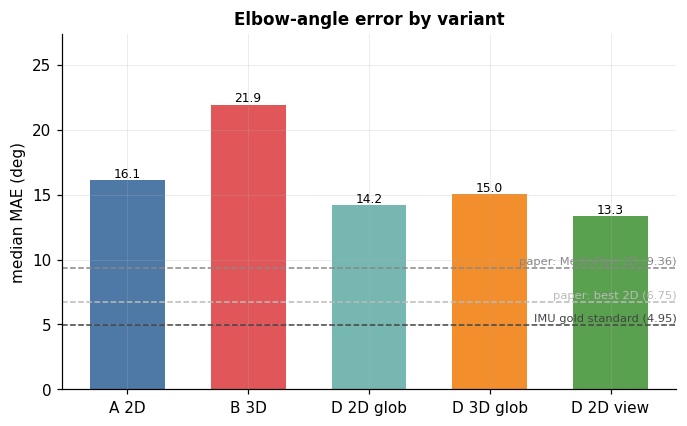

  saved F2_by_exercise.png


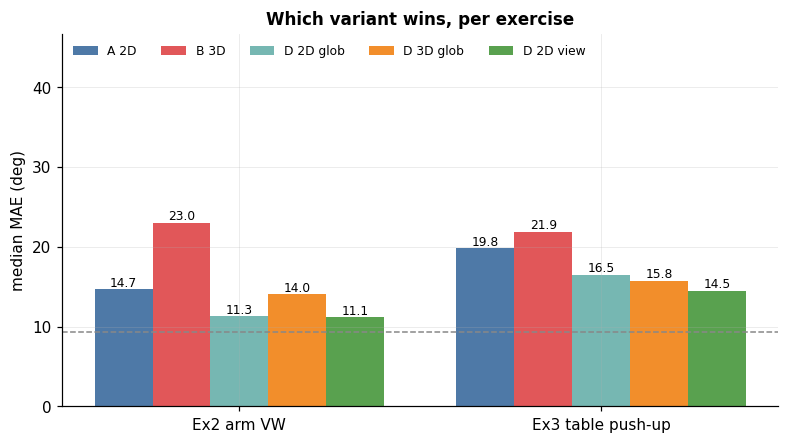

  saved F3_by_view.png


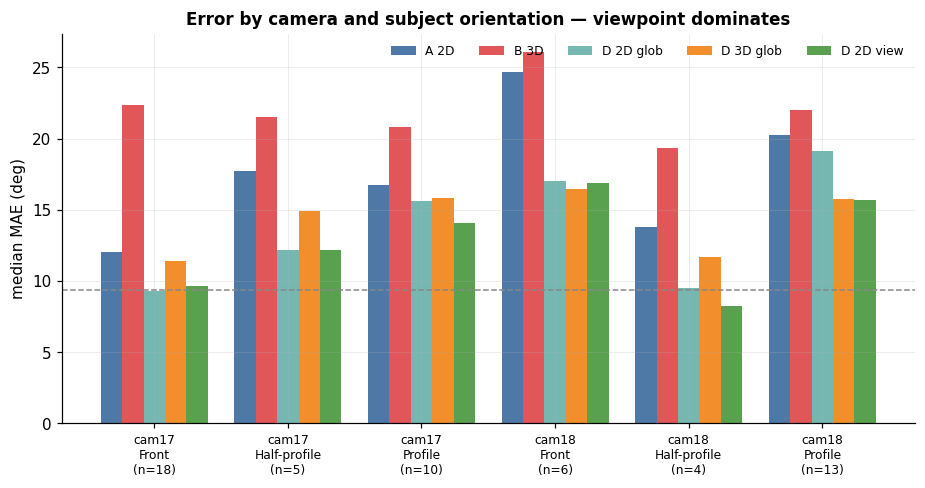

  saved F4_bias.png


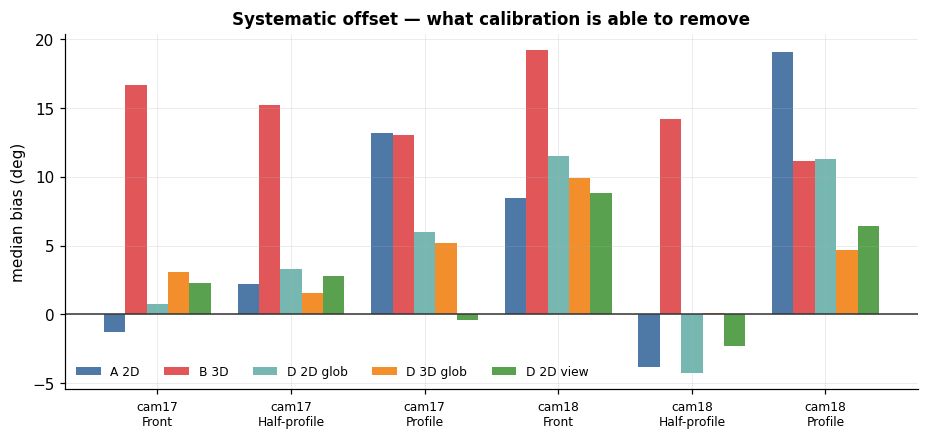

  saved F5_error_vs_angle.png


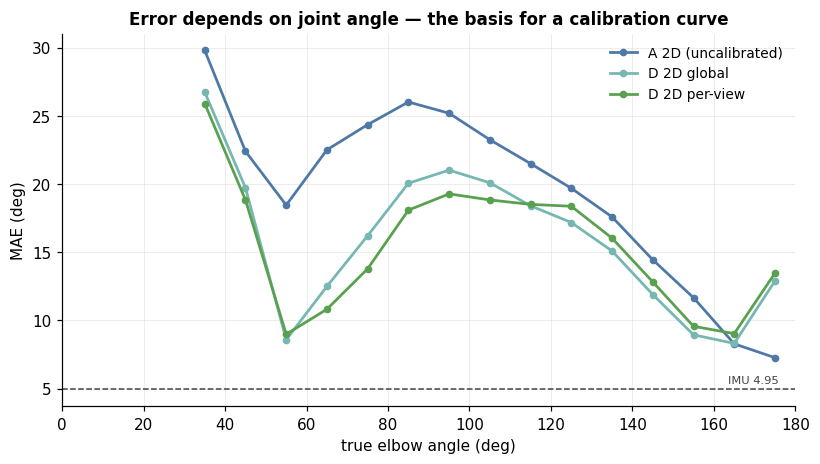

  saved F6_timeseries.png


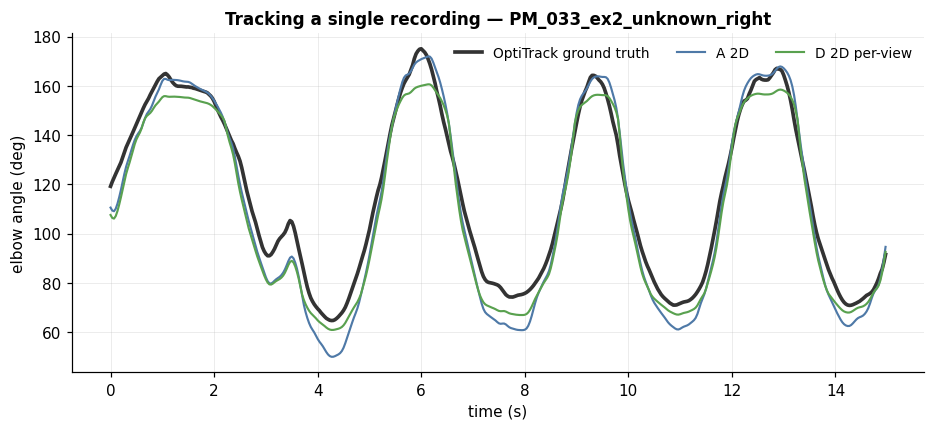

  saved F7_bland_altman.png


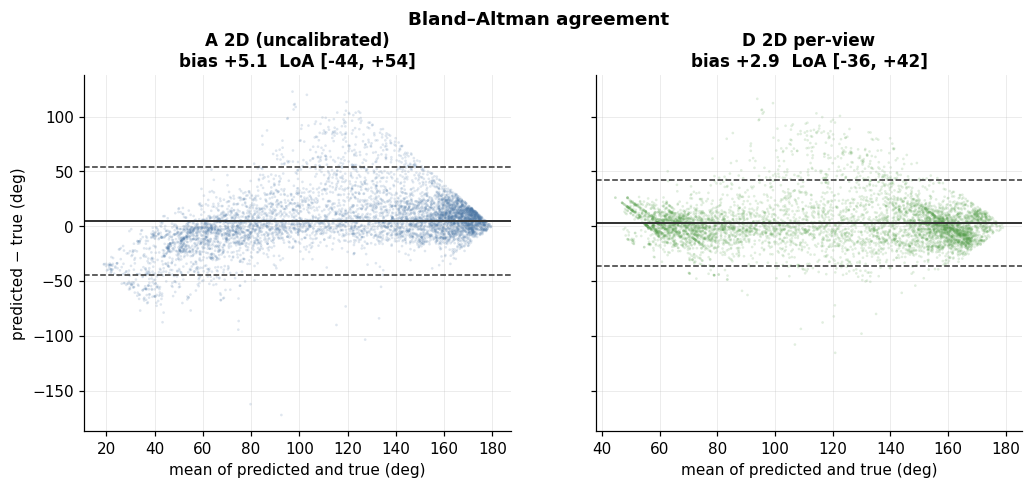

/tmp/ipykernel_2366/3452530746.py:257: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=['raw', 'global cal', 'per-view cal'],


  saved F8_rom_fidelity.png


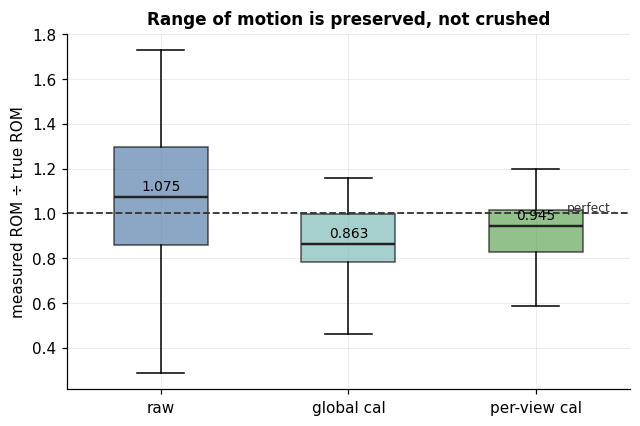

  saved F9_exclusions.png


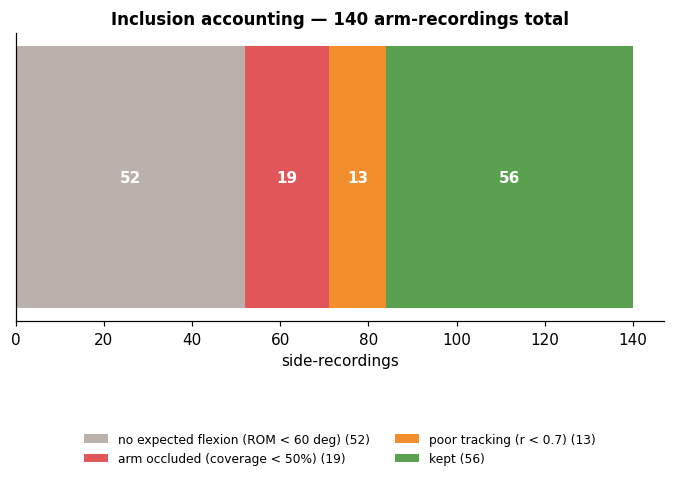


scanning coverage for near/far-arm table ...

TABLE 8 — median landmark coverage, near vs far arm
side      left  right
ex cam               
1  cam17  53.5  100.0
   cam18  97.3   32.5
2  cam17  88.9  100.0
   cam18  99.9   41.1
3  cam17   3.2   95.8
   cam18  90.7   94.7
  saved F10_coverage.png


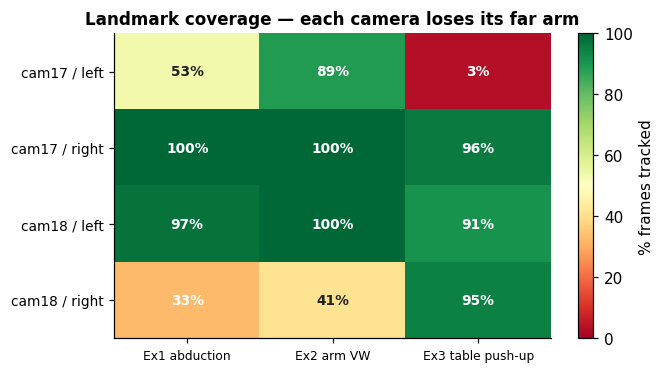


HEADLINE
best variant overall   : D_2D_PerView  MAE 13.33 deg
frontal view (n=18)  : 9.61 deg   (paper 9.36)
per exercise           : Ex2 arm VW -> D_2D_PerView, Ex3 table push-up -> D_2D_PerView

figures : /content/drive/MyDrive/rehab24_results_3d/report_figs
tables  : /content/drive/MyDrive/rehab24_results_3d/report_tables.xlsx


/tmp/ipykernel_2366/3452530746.py:321: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  t1.to_excel(xl, 'T1_overall');     t2.to_excel(xl, 'T2_exercise')
/tmp/ipykernel_2366/3452530746.py:322: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  t3.to_excel(xl, 'T3_view');        t4.to_excel(xl, 'T4_bias')
/tmp/ipykernel_2366/3452530746.py:323: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  t5.to_excel(xl, 'T5_exclusions', index=False)
/tmp/ipykernel_2366/3452530746.py:324: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  if lopo is not None: lopo.round(2).to_excel(xl, 'T6_LOPO', index=False)
/tmp/ipykernel_2366/3452530746.py:325: FutureWarni

In [17]:
# ============================================================
# COMPREHENSIVE REPORT — tables + figures
# Run AFTER Step 5 (needs: df, aligned_cache, recordings, fit_curve, ...)
# ============================================================
import os, json, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

FIGDIR = os.path.join(RESULTS, 'report_figs'); os.makedirs(FIGDIR, exist_ok=True)
DO_COVERAGE = True          # set False to skip the near/far-arm scan (~20 s)

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': .25, 'grid.linewidth': .6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})
ORDER = ['A_2D_Base', 'B_3D_World', 'D_2D_Calibrated', 'D_3D_Calibrated', 'D_2D_PerView']
COL   = {'A_2D_Base':'#4E79A7', 'B_3D_World':'#E15759', 'D_2D_Calibrated':'#76B7B2',
         'D_3D_Calibrated':'#F28E2B', 'D_2D_PerView':'#59A14F'}
SHORT = {'A_2D_Base':'A 2D', 'B_3D_World':'B 3D', 'D_2D_Calibrated':'D 2D glob',
         'D_3D_Calibrated':'D 3D glob', 'D_2D_PerView':'D 2D view'}
PAPER_MP, PAPER_BEST, IMU = 9.36, 6.75, 4.95      # Sensors 2023: Table 8 / ref [29]

def save(fig, name):
    p = os.path.join(FIGDIR, name); fig.savefig(p); print('  saved', name); return p

def bar_labels(ax, bars, fmt='{:.1f}'):
    for b in bars:
        h = b.get_height()
        if np.isfinite(h):
            ax.text(b.get_x()+b.get_width()/2, h, fmt.format(h),
                    ha='center', va='bottom', fontsize=8)

# ---------- prepare ----------
df = pd.concat([pd.read_csv(f) for f in
                __import__('glob').glob(os.path.join(RESULTS, 'variant_*.csv'))],
               ignore_index=True)
df['subj'] = df['view'].str.replace('/cam18', '', regex=False)
present = [v for v in ORDER if v in set(df.variant)]
EXN = {1:'Ex1 abduction', 2:'Ex2 arm VW', 3:'Ex3 table push-up'}

print('='*78); print('DATA'); print('='*78)
print(f'rows {len(df)} | variants {len(present)} | recordings {len(df)//max(len(present),1)}')

# ---------- frame-level calibrated predictions (for the frame-wise figures) ----------
print('\nfitting LOPO curves for frame-level figures ...')
FR = []
for it in aligned_cache:
    me   = it['meta']
    pool = [x for x in aligned_cache if x['meta']['person'] != me['person']]
    same = [x for x in pool if x['meta']['view'] == me['view']] or pool
    rec  = dict(meta=me, truth=it['truth_3d'], raw=it['pred_2d'], raw3=it['pred_3d'])
    for train, key in ((pool, 'glob'), (same, 'view')):
        p = np.concatenate([x['pred_2d'] for x in train])
        t = np.concatenate([x['truth_3d'] for x in train])
        v = np.isfinite(p) & np.isfinite(t)
        try:
            prm = fit_curve(p[v], t[v], min_count=15)
            rec[key] = apply_calibration(it['pred_2d'], prm)
        except ValueError:
            rec[key] = it['pred_2d']
    FR.append(rec)
print(f'  {len(FR)} recordings prepared')

def stack(key):
    p = np.concatenate([r[key]   for r in FR])
    t = np.concatenate([r['truth'] for r in FR])
    m = np.isfinite(p) & np.isfinite(t)
    return p[m], t[m]

# ================================================================
# TABLES
# ================================================================
print('\n'+'='*78); print('TABLE 1 — overall, by variant'); print('='*78)
t1 = (df.groupby('variant')[['mae','rmse','bias','r','coverage','share_gt20']]
        .median().round(2).reindex(present))
t1['vs_paper'] = (t1['mae'] - PAPER_MP).round(2)
print(t1.to_string())
print(f'\nreference: MediaPipe 2D {PAPER_MP}  |  best 2D (AlphaPose) {PAPER_BEST}  |  IMU {IMU} (RMSE)')

print('\n'+'='*78); print('TABLE 2 — MAE by exercise  (which variant wins where)'); print('='*78)
t2 = df.groupby(['ex','variant'])['mae'].median().unstack().reindex(columns=present).round(2)
t2['BEST'] = t2.idxmin(axis=1)
t2['best_mae'] = t2[present].min(axis=1).round(2)
t2['gain_vs_A'] = (t2['A_2D_Base'] - t2['best_mae']).round(2)
t2['n'] = df[df.variant==present[0]].groupby('ex').size()
print(t2.to_string())

print('\n'+'='*78); print('TABLE 3 — MAE by camera x subject orientation'); print('='*78)
t3 = (df.groupby(['cam','subj','variant'])['mae'].median()
        .unstack().reindex(columns=present).round(2))
t3['BEST'] = t3.idxmin(axis=1)
t3['n'] = df[df.variant==present[0]].groupby(['cam','subj']).size()
print(t3.to_string())

print('\n'+'='*78); print('TABLE 4 — bias by camera x orientation (systematic offset)'); print('='*78)
t4 = (df.groupby(['cam','subj','variant'])['bias'].median()
        .unstack().reindex(columns=present).round(2))
print(t4.to_string())

print('\n'+'='*78); print('TABLE 5 — inclusion / exclusion accounting'); print('='*78)
g = globals()
t5 = pd.DataFrame([
    ('no expected flexion (ROM < 60 deg)', g.get('skipped_static', np.nan)),
    ('arm occluded (coverage < 50%)',      g.get('skipped_cov',    np.nan)),
    ('poor tracking (r < 0.7)',            g.get('skipped_align',  np.nan)),
    ('kept',                               len(df[df.variant==present[0]])),
], columns=['reason','side_recordings'])
t5['pct'] = (100*t5.side_recordings/t5.side_recordings.sum()).round(1)
print(t5.to_string(index=False))
print('\nmethod follows Aguilar-Ortega et al. (Sensors 2023) p.10: angles evaluated only')
print('where flexion is expected and every method delivered a valid estimation.')

print('\n'+'='*78); print('TABLE 6 — LOPO calibration, per person'); print('='*78)
try:
    from calibration import leave_one_person_out
    lopo = leave_one_person_out(
        [dict(person=r['meta']['person'], raw=r['raw'], truth=r['truth']) for r in FR])
    print(lopo[['person','n','mae_raw','mae_cal','gt20_raw','gt20_cal',
                'range_raw','range_cal','range_truth']].round(2).to_string(index=False))
    print(f"\nmedian MAE  {lopo.mae_raw.median():.2f} -> {lopo.mae_cal.median():.2f}"
          f"   |  >20deg {lopo.gt20_raw.median():.1f}% -> {lopo.gt20_cal.median():.1f}%"
          f"   |  improved for {int((lopo.mae_cal<lopo.mae_raw).sum())}/{len(lopo)} persons")
except Exception as e:
    lopo = None; print('LOPO skipped:', e)

print('\n'+'='*78); print('TABLE 7 — ROM fidelity (calibration must not crush range)'); print('='*78)
def rom(a):
    a = np.asarray(a, float)
    return np.nanpercentile(a,95)-np.nanpercentile(a,5) if np.isfinite(a).any() else np.nan
romr = {k: [] for k in ('raw','glob','view')}
for r in FR:
    t = rom(r['truth'])
    if np.isfinite(t) and t > 0:
        for k in romr: romr[k].append(rom(r[k])/t)
t7 = pd.DataFrame({k: pd.Series(v).describe()[['50%','min','max']] for k,v in romr.items()}).T
t7.columns = ['median','min','max']; t7['|1-median|'] = (1-t7['median']).abs().round(3)
print(t7.round(3).to_string())

# ================================================================
# FIGURES
# ================================================================
print('\n'+'='*78); print('FIGURES'); print('='*78)

# --- F1: overall variant comparison -------------------------------
fig, ax = plt.subplots(figsize=(7.2, 4.2))
vals = t1.loc[present, 'mae']
b = ax.bar([SHORT[v] for v in present], vals, color=[COL[v] for v in present], width=.62)
bar_labels(ax, b)
for y, lab, c in ((PAPER_MP,'paper: MediaPipe 2D (9.36)','#888'),
                  (PAPER_BEST,'paper: best 2D (6.75)','#bbb'),
                  (IMU,'IMU gold standard (4.95)','#444')):
    ax.axhline(y, ls='--', lw=1, color=c)
    ax.text(len(present)-.45, y+.25, lab, ha='right', fontsize=7.5, color=c)
ax.set_ylabel('median MAE (deg)'); ax.set_title('Elbow-angle error by variant')
ax.yaxis.set_major_locator(MultipleLocator(5)); ax.set_ylim(0, max(vals)*1.25)
save(fig, 'F1_variant_overall.png'); plt.show()

# --- F2: MAE by exercise ------------------------------------------
exs = sorted(df.ex.dropna().unique())
fig, ax = plt.subplots(figsize=(8.4, 4.4))
w = .8/len(present); x = np.arange(len(exs))
for i, v in enumerate(present):
    y = [t2.loc[e, v] if e in t2.index else np.nan for e in exs]
    bb = ax.bar(x+i*w-.4+w/2, y, w, label=SHORT[v], color=COL[v])
    bar_labels(ax, bb)
ax.axhline(PAPER_MP, ls='--', lw=1, color='#888')
ax.set_xticks(x); ax.set_xticklabels([EXN.get(int(e), f'Ex{int(e)}') for e in exs])
ax.set_ylabel('median MAE (deg)'); ax.set_title('Which variant wins, per exercise')
ax.legend(ncol=len(present), fontsize=8, frameon=False, loc='upper left')
ax.set_ylim(0, df.mae.max()*.95)
save(fig, 'F2_by_exercise.png'); plt.show()

# --- F3: MAE by viewpoint -----------------------------------------
cells = list(t3.index)
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(cells))
for i, v in enumerate(present):
    y = [t3.loc[c, v] for c in cells]
    ax.bar(x+i*w-.4+w/2, y, w, label=SHORT[v], color=COL[v])
ax.axhline(PAPER_MP, ls='--', lw=1, color='#888')
ax.set_xticks(x)
ax.set_xticklabels([f'{c[0]}\n{c[1]}\n(n={int(t3.loc[c,"n"])})' for c in cells], fontsize=8)
ax.set_ylabel('median MAE (deg)')
ax.set_title('Error by camera and subject orientation — viewpoint dominates')
ax.legend(ncol=len(present), fontsize=8, frameon=False)
save(fig, 'F3_by_view.png'); plt.show()

# --- F4: bias (systematic offset) ---------------------------------
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, v in enumerate(present):
    y = [t4.loc[c, v] for c in cells]
    ax.bar(x+i*w-.4+w/2, y, w, label=SHORT[v], color=COL[v])
ax.axhline(0, color='#333', lw=1)
ax.set_xticks(x); ax.set_xticklabels([f'{c[0]}\n{c[1]}' for c in cells], fontsize=8)
ax.set_ylabel('median bias (deg)')
ax.set_title('Systematic offset — what calibration is able to remove')
ax.legend(ncol=len(present), fontsize=8, frameon=False)
save(fig, 'F4_bias.png'); plt.show()

# --- F5: error vs true angle (replicates paper Fig. 18) -----------
edges = np.arange(0, 190, 10)
fig, ax = plt.subplots(figsize=(8.6, 4.4))
for key, lab, c in (('raw','A 2D (uncalibrated)',COL['A_2D_Base']),
                    ('glob','D 2D global',COL['D_2D_Calibrated']),
                    ('view','D 2D per-view',COL['D_2D_PerView'])):
    p, t = stack(key)
    idx = np.clip(np.digitize(t, edges)-1, 0, len(edges)-2)
    m = [np.abs(p[idx==b]-t[idx==b]).mean() if (idx==b).sum() > 50 else np.nan
         for b in range(len(edges)-1)]
    ax.plot(edges[:-1]+5, m, 'o-', ms=4, lw=1.8, label=lab, color=c)
ax.axhline(IMU, ls='--', lw=1, color='#444')
ax.text(176, IMU+.4, 'IMU 4.95', ha='right', fontsize=7.5, color='#444')
ax.set_xlabel('true elbow angle (deg)'); ax.set_ylabel('MAE (deg)')
ax.set_title('Error depends on joint angle — the basis for a calibration curve')
ax.legend(frameon=False, fontsize=9); ax.set_xlim(0, 180)
save(fig, 'F5_error_vs_angle.png'); plt.show()

# --- F6: predicted vs ground truth, representative recording ------
front = [r for r in FR if r['meta'].get('cam')=='cam17'
         and 'Front' in str(r['meta'].get('view'))]
pick = (sorted(front, key=lambda r: np.nanmean(np.abs(r['raw']-r['truth'])))[len(front)//2]
        if front else FR[0])
n = min(len(pick['truth']), 450); tt = np.arange(n)/30.0
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(tt, pick['truth'][:n], lw=2.4, color='#333', label='OptiTrack ground truth')
ax.plot(tt, pick['raw'][:n],  lw=1.4, color=COL['A_2D_Base'],   label='A 2D')
ax.plot(tt, pick['view'][:n], lw=1.4, color=COL['D_2D_PerView'], label='D 2D per-view')
ax.set_xlabel('time (s)'); ax.set_ylabel('elbow angle (deg)')
ax.set_title(f"Tracking a single recording — {pick['meta']['recording']}")
ax.legend(frameon=False, fontsize=9, ncol=3)
save(fig, 'F6_timeseries.png'); plt.show()

# --- F7: Bland-Altman ---------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for axx, (key, lab, c) in zip(axes, (('raw','A 2D (uncalibrated)',COL['A_2D_Base']),
                                     ('view','D 2D per-view',COL['D_2D_PerView']))):
    p, t = stack(key); d = p-t; mean = (p+t)/2
    s = np.random.default_rng(0).choice(len(d), min(6000, len(d)), replace=False)
    axx.scatter(mean[s], d[s], s=3, alpha=.18, color=c, edgecolors='none')
    mu, sd = d.mean(), d.std()
    axx.axhline(mu, color='#333', lw=1.3)
    axx.axhline(mu+1.96*sd, color='#333', lw=1, ls='--')
    axx.axhline(mu-1.96*sd, color='#333', lw=1, ls='--')
    axx.set_title(f'{lab}\nbias {mu:+.1f}  LoA [{mu-1.96*sd:+.0f}, {mu+1.96*sd:+.0f}]')
    axx.set_xlabel('mean of predicted and true (deg)')
axes[0].set_ylabel('predicted − true (deg)')
fig.suptitle('Bland–Altman agreement', y=1.02, fontweight='bold')
save(fig, 'F7_bland_altman.png'); plt.show()

# --- F8: ROM fidelity ---------------------------------------------
fig, ax = plt.subplots(figsize=(6.6, 4.2))
data = [romr['raw'], romr['glob'], romr['view']]
bp = ax.boxplot(data, labels=['raw', 'global cal', 'per-view cal'],
                patch_artist=True, widths=.5, showfliers=False)
for patch, c in zip(bp['boxes'], [COL['A_2D_Base'], COL['D_2D_Calibrated'], COL['D_2D_PerView']]):
    patch.set_facecolor(c); patch.set_alpha(.65)
for med in bp['medians']: med.set_color('#222'); med.set_linewidth(1.6)
ax.axhline(1.0, ls='--', color='#333', lw=1.2)
ax.text(3.4, 1.01, 'perfect', ha='right', fontsize=8, color='#333')
ax.set_ylabel('measured ROM ÷ true ROM')
ax.set_title('Range of motion is preserved, not crushed')
for i, v in enumerate(data, 1):
    ax.text(i, np.median(v)+.03, f'{np.median(v):.3f}', ha='center', fontsize=9)
save(fig, 'F8_rom_fidelity.png'); plt.show()

# --- F9: exclusion accounting -------------------------------------
fig, ax = plt.subplots(figsize=(7.6, 3.4))
cols = ['#BAB0AC', '#E15759', '#F28E2B', '#59A14F']
left = 0
for (_, row), c in zip(t5.iterrows(), cols):
    ax.barh(0, row.side_recordings, left=left, color=c, height=.5,
            label=f"{row.reason} ({int(row.side_recordings)})")
    if row.side_recordings > 6:
        ax.text(left+row.side_recordings/2, 0, int(row.side_recordings),
                ha='center', va='center', color='white', fontweight='bold')
    left += row.side_recordings
ax.set_yticks([]); ax.set_xlabel('side-recordings')
ax.set_title(f'Inclusion accounting — {int(t5.side_recordings.sum())} arm-recordings total')
ax.legend(fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(.5, -.35), ncol=2)
ax.grid(False)
save(fig, 'F9_exclusions.png'); plt.show()

# --- F10: near vs far arm trackability ----------------------------
if DO_COVERAGE:
    print('\nscanning coverage for near/far-arm table ...')
    cov_rows = []
    for rec in recordings:
        lm, world, size, fps = get_3d_landmarks(rec)
        lmm = mask_low_visibility(lm, threshold=THRESHOLD)
        for side in ('right', 'left'):
            pa = angles_2d.elbow_angle(lmm, side=side, size=size)
            cov_rows.append(dict(ex=rec['exercise'], cam=rec.get('cam_label'),
                                 side=side, cov=100*np.isfinite(pa).mean()))
    cv = pd.DataFrame(cov_rows)
    t8 = cv.groupby(['ex','cam','side'])['cov'].median().unstack().round(1)
    print('\n'+'='*78); print('TABLE 8 — median landmark coverage, near vs far arm'); print('='*78)
    print(t8.to_string())

    piv = cv.pivot_table(index=['cam','side'], columns='ex', values='cov', aggfunc='median')
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    im = ax.imshow(piv.values, cmap='RdYlGn', vmin=0, vmax=100, aspect='auto')
    ax.set_xticks(range(len(piv.columns)))
    ax.set_xticklabels([EXN.get(int(c), c) for c in piv.columns], fontsize=8)
    ax.set_yticks(range(len(piv.index)))
    ax.set_yticklabels([f'{a} / {b}' for a, b in piv.index], fontsize=9)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            ax.text(j, i, f'{v:.0f}%', ha='center', va='center', fontsize=9,
                    color='white' if v < 35 or v > 85 else '#222', fontweight='bold')
    ax.set_title('Landmark coverage — each camera loses its far arm')
    ax.grid(False); fig.colorbar(im, label='% frames tracked')
    save(fig, 'F10_coverage.png'); plt.show()

# ---------- export ----------
with pd.ExcelWriter(os.path.join(RESULTS, 'report_tables.xlsx')) as xl:
    t1.to_excel(xl, 'T1_overall');     t2.to_excel(xl, 'T2_exercise')
    t3.to_excel(xl, 'T3_view');        t4.to_excel(xl, 'T4_bias')
    t5.to_excel(xl, 'T5_exclusions', index=False)
    if lopo is not None: lopo.round(2).to_excel(xl, 'T6_LOPO', index=False)
    t7.to_excel(xl, 'T7_ROM')
    if DO_COVERAGE: t8.to_excel(xl, 'T8_coverage')

print('\n'+'='*78); print('HEADLINE'); print('='*78)
bestv = t1.mae.idxmin()
print(f'best variant overall   : {bestv}  MAE {t1.mae.min():.2f} deg')
f = df[(df.variant==bestv) & (df.cam=='cam17') & (df.subj=='Front')]
if len(f): print(f'frontal view (n={len(f)})  : {f.mae.median():.2f} deg   (paper {PAPER_MP})')
print(f'per exercise           : ' + ', '.join(f'{EXN.get(int(e),e)} -> {t2.loc[e,"BEST"]}'
                                               for e in t2.index))
print(f'\nfigures : {FIGDIR}')
print(f'tables  : {os.path.join(RESULTS, "report_tables.xlsx")}')

In [18]:
# z-axis noise check — uses the cached npz, no re-extraction
import numpy as np
rows = []
for rec in recordings[:20]:
    lm, world, size, fps = get_3d_landmarks(rec)
    w = mask_world_like(world, mask_low_visibility(lm, threshold=THRESHOLD))
    for j, name in [(14, 'R.elbow'), (16, 'R.wrist'), (12, 'R.shoulder')]:
        for a, ax in enumerate('xyz'):
            v = w[:, j, a]
            d = np.abs(np.diff(v[np.isfinite(v)]))      # frame-to-frame jitter
            if len(d) > 50:
                rows.append(dict(joint=name, axis=ax, jitter_mm=1000*np.median(d)))
import pandas as pd
print(pd.DataFrame(rows).groupby(['joint','axis'])['jitter_mm'].median().unstack().round(2))

axis           x     y     z
joint                       
R.elbow     1.11  1.63  2.10
R.shoulder  0.36  0.42  0.97
R.wrist     1.58  2.08  3.23
